# 08 - Exploratory Data Analysis: OrganAMNIST

Third and final subset. Like PneumoniaMNIST, OrganAMNIST is **grayscale** (abdominal CT), but like DermaMNIST it is **multi-class** (11 organ classes) and considerably **larger**. This combination — more data, more classes, single channel — lets us test whether more training data changes the patterns seen in phases 1 and 2 (ranking reversal, severe sensitivity to class imbalance).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import get_dataset, get_spec, compute_normalization_stats
from src.metrics import majority_class_baseline
from src.utils import set_seed

set_seed(42)
FLAG = "organamnist"
SIZE = 28


## 1. Dataset specification

In [2]:
spec = get_spec(FLAG)
print(spec)
print(f"\nTask type: {spec.task} | n_channels: {spec.n_channels} | n_classes: {spec.n_classes}")

DatasetSpec(flag='organamnist', task='multi-class', n_channels=1, n_classes=11, labels={'0': 'bladder', '1': 'femur-left', '2': 'femur-right', '3': 'heart', '4': 'kidney-left', '5': 'kidney-right', '6': 'liver', '7': 'lung-left', '8': 'lung-right', '9': 'pancreas', '10': 'spleen'})

Task type: multi-class | n_channels: 1 | n_classes: 11


## 2. Loading the splits

In [3]:
splits = {s: get_dataset(FLAG, s, size=SIZE, root="../data") for s in ["train", "val", "test"]}
for name, ds in splits.items():
    print(f"{name:>5}: {len(ds):>6} images | image array shape: {ds.imgs.shape}")

100%|██████████| 38.2M/38.2M [00:38<00:00, 1.01MB/s]


train:  34561 images | image array shape: (34561, 28, 28)
  val:   6491 images | image array shape: (6491, 28, 28)
 test:  17778 images | image array shape: (17778, 28, 28)


## 3. Class distribution

11 classes (organs). Comparing the imbalance ratio here to PneumoniaMNIST (~3x) and DermaMNIST (~59x) tells us where this dataset sits on that spectrum.

split,train,val,test,train_proportion
class,,,,
liver,6164,1033,3285,0.1784
kidney-left,3963,568,2064,0.1147
lung-right,3929,1009,1813,0.1137
lung-left,3919,1033,1747,0.1134
kidney-right,3817,637,1965,0.1104
spleen,3561,511,1884,0.1030
pancreas,3031,529,1622,0.0877
bladder,1956,321,1036,0.0566
heart,1474,392,785,0.0426



Imbalance ratio (train): 4.5x (PneumoniaMNIST was ~2.9x, DermaMNIST was ~58.7x)


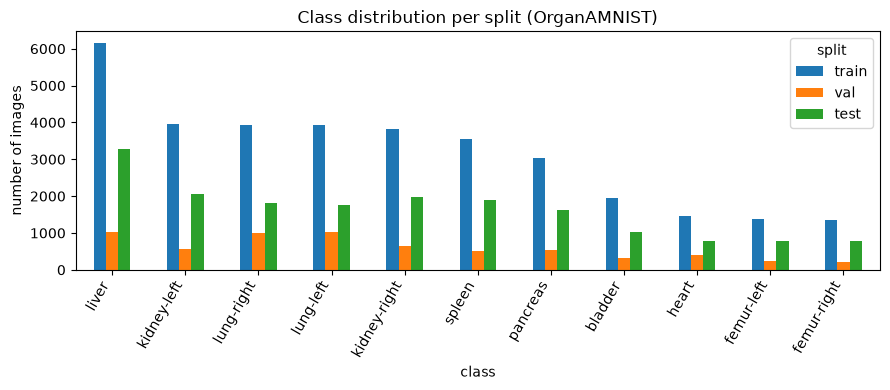

In [4]:
rows = []
for name, ds in splits.items():
    labels = ds.labels.flatten()
    for cls, count in zip(*np.unique(labels, return_counts=True)):
        rows.append({"split": name, "class": spec.labels[str(cls)], "n": count})
df = pd.DataFrame(rows)
pivot = df.pivot(index="class", columns="split", values="n")[["train", "val", "test"]]
pivot["train_proportion"] = (pivot["train"] / pivot["train"].sum()).round(4)
pivot = pivot.sort_values("train", ascending=False)
display(pivot)

imbalance_ratio = pivot["train"].max() / pivot["train"].min()
print(f"\nImbalance ratio (train): {imbalance_ratio:.1f}x "
     f"(PneumoniaMNIST was ~2.9x, DermaMNIST was ~58.7x)")

fig, ax = plt.subplots(figsize=(9, 4))
pivot[["train", "val", "test"]].plot(kind="bar", ax=ax)
ax.set_ylabel("number of images"); ax.set_title("Class distribution per split (OrganAMNIST)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.show()

## 4. Majority-class baseline

In [5]:
for name, ds in splits.items():
    baseline = majority_class_baseline(ds.labels.flatten())
    print(f"{name:>5}: always predicting the majority class gets {baseline:.4f} accuracy")

train: always predicting the majority class gets 0.1784 accuracy
  val: always predicting the majority class gets 0.1591 accuracy
 test: always predicting the majority class gets 0.1848 accuracy


## 5. Visual examples

One example per class (grayscale, like PneumoniaMNIST).

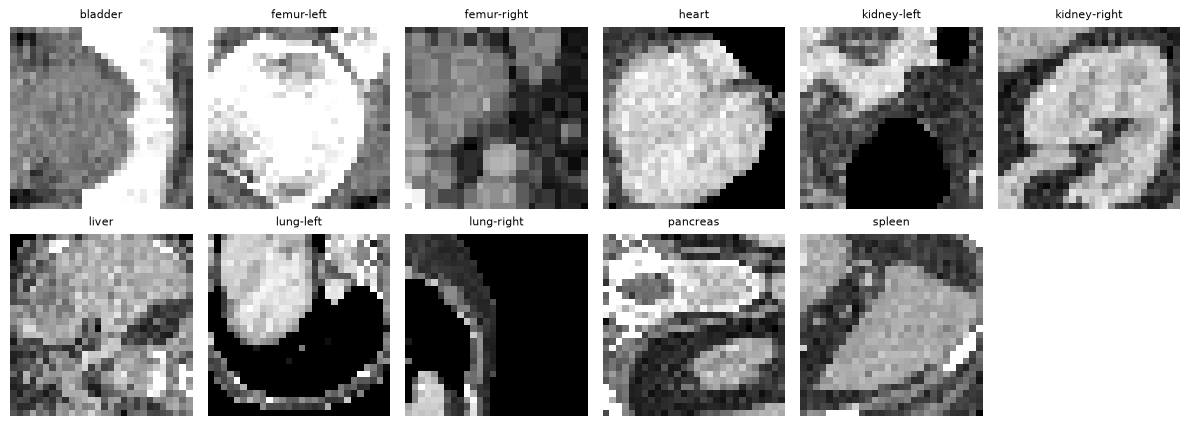

In [6]:
n_classes = spec.n_classes
n_cols = 6
n_rows = (n_classes + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.0 * n_cols, 2.2 * n_rows))
axes = axes.flatten()
train = splits["train"]
labels_flat = train.labels.flatten()
for i in range(n_classes):
    idx = np.where(labels_flat == i)[0]
    ax = axes[i]
    if len(idx) > 0:
        ax.imshow(train.imgs[idx[0]], cmap="gray")
    ax.axis("off")
    ax.set_title(spec.labels[str(i)], fontsize=8)
for ax in axes[n_classes:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Pixel statistics

Single channel, like PneumoniaMNIST — `compute_normalization_stats` returns a one-element mean/std list here, not three as in DermaMNIST.

mean: 0.4680 | std: 0.2974


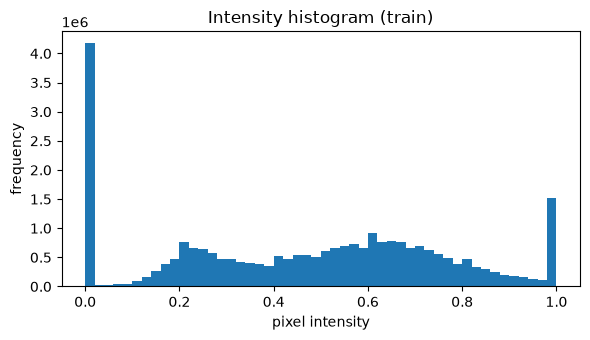

In [7]:
mean, std = compute_normalization_stats(FLAG, size=SIZE, root="../data")
print(f"mean: {mean[0]:.4f} | std: {std[0]:.4f}")

train = splits["train"]
imgs = train.imgs.astype(np.float32) / 255.0
plt.figure(figsize=(6, 3.5))
plt.hist(imgs.flatten(), bins=50)
plt.xlabel("pixel intensity"); plt.ylabel("frequency")
plt.title("Intensity histogram (train)")
plt.tight_layout(); plt.show()

## 7. Observations

OrganAMNIST sits between PneumoniaMNIST and DermaMNIST on the imbalance
spectrum: a 4.5x ratio between the largest (liver, 6,164) and smallest
(femur-right, 1,357) training classes, much milder than DermaMNIST's 58.7x.
Even the rarest class here has more training examples (1,357) than
PneumoniaMNIST's entire minority class (1,214 normal), whereas DermaMNIST's
rarest class has only 80 images.

The majority-class baseline varies moderately between splits (0.178 train,
0.159 val, 0.185 test), far less than PneumoniaMNIST's train-to-test shift.

Visually, organs are far more distinguishable than DermaMNIST's lesion
types: bone (femur) appears as a bright, sharply defined region, lungs show
large dark (air-filled) areas, and the heart is a round central blob. The
pixel histogram has two modes (near 0 for background/air, near 1 for
bone/dense tissue) and a higher standard deviation (0.297) than
PneumoniaMNIST (0.168). Together, the larger per-class sample sizes and the
stronger visual separation suggest this subset should be easier than
DermaMNIST. Since the two differ in both respects, the training results
cannot tell us which factor matters more.